# Generalized Linear Models (GLM) and Advanced Techniques

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. What is a GLM?

A **Generalized Linear Model (GLM)** extends linear regression to response variables that are **not normally distributed** — counts, yes/no outcomes, positive skewed amounts.

GLMs have three components:

1. **Random component**: $Y_i$ follows a distribution from the **exponential family** (Normal, Binomial, Poisson, Gamma, ...)
2. **Systematic component**: a linear predictor
$$
\eta_i = \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip}
$$
3. **Link function** $g(\cdot)$ connecting the expected value to the linear predictor:
$$
g(\mathbb{E}[Y_i]) = \eta_i
$$

## 2. Common GLM Families and Link Functions

| Family | Response type | Canonical link | Inverse link (prediction) |
|---|---|---|---|
| Gaussian | continuous | identity: $\mu$ | $\mu = \eta$ |
| Binomial | binary / proportions | logit: $\log\frac{\mu}{1-\mu}$ | $\mu = \frac{1}{1+e^{-\eta}}$ |
| Poisson | counts | log: $\log \mu$ | $\mu = e^{\eta}$ |
| Gamma | positive, right-skewed | inverse: $1/\mu$ (log is common in practice) | $\mu = 1/\eta$ |

- Linear regression is a GLM with the Gaussian family and identity link.
- Logistic regression (Lesson 19) is a GLM with the binomial family and logit link.
- **Poisson regression** models count data; because of the log link, $e^{\beta_j}$ is a **rate ratio**.

## 3. GLM Formulation

$$
Y_i \sim \text{ExponentialFamily}(\mu_i, \phi), \qquad g(\mu_i) = \eta_i = \beta_0 + \sum_{j=1}^{p} \beta_j x_{ij}
$$

- $\mu_i = \mathbb{E}[Y_i]$; $\phi$ is a dispersion parameter (fixed at 1 for Poisson and Binomial)
- Coefficients are estimated by **Maximum Likelihood** (via iteratively reweighted least squares)
- Model fit is summarised by the **deviance**, which plays the role of the residual sum of squares

## 4. Poisson Regression: Emails per Day

In [2]:
set.seed(123)
n_days <- 80
glm_data <- data.frame(Hours = round(runif(n_days, 3, 11), 1))
glm_data$Emails <- rpois(n_days, lambda = exp(-0.5 + 0.28 * glm_data$Hours))   # true rate ratio = e^0.28
head(glm_data)

poisson_model <- glm(Emails ~ Hours, data = glm_data, family = poisson)
summary(poisson_model)

,Hours,Emails
,<dbl>,<int>
1,5.3,1
2,9.3,9
3,6.3,3
4,10.1,12
5,10.5,10
6,3.4,3



Call:
glm(formula = Emails ~ Hours, family = poisson, data = glm_data)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -0.33822    0.20377   -1.66    0.097 .  
Hours        0.25757    0.02393   10.76   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 198.903  on 79  degrees of freedom
Residual deviance:  71.213  on 78  degrees of freedom
AIC: 331.65

Number of Fisher Scoring iterations: 4


In [3]:
cat("Rate ratio per extra work hour: exp(beta) =", round(exp(coef(poisson_model)["Hours"]), 3),
    "-> about", round(100 * (exp(coef(poisson_model)["Hours"]) - 1)), "% more emails per hour worked\n")
cat("Expected emails for a 4h / 8h / 10h day:",
    round(predict(poisson_model, data.frame(Hours = c(4, 8, 10)), type = "response"), 2), "\n")

Rate ratio per extra work hour: exp(beta) = 1.294 -> about 29 % more emails per hour worked


Expected emails for a 4h / 8h / 10h day: 2 5.6 9.37 


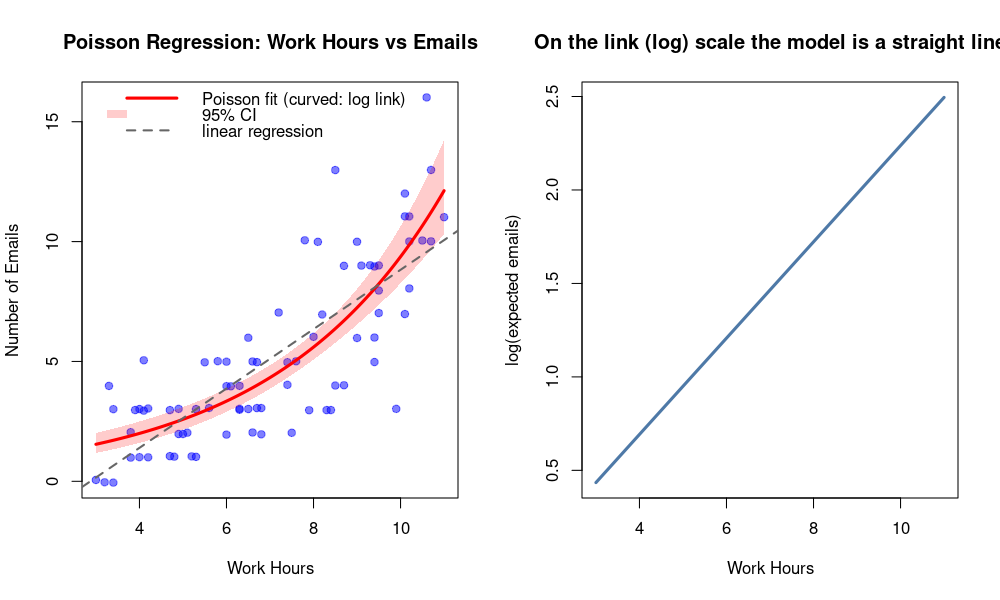

In [4]:
grid <- data.frame(Hours = seq(3, 11, length.out = 200))
pred <- predict(poisson_model, grid, type = "link", se.fit = TRUE)
fit  <- exp(pred$fit)
lwr  <- exp(pred$fit - 1.96 * pred$se.fit); upr <- exp(pred$fit + 1.96 * pred$se.fit)

par(mfrow = c(1, 2))
plot(glm_data$Hours, jitter(glm_data$Emails, 0.3), pch = 19, col = adjustcolor("blue", 0.5),
     xlab = "Work Hours", ylab = "Number of Emails", main = "Poisson Regression: Work Hours vs Emails")
polygon(c(grid$Hours, rev(grid$Hours)), c(lwr, rev(upr)), col = adjustcolor("red", 0.2), border = NA)
lines(grid$Hours, fit, col = "red", lwd = 3)
abline(lm(Emails ~ Hours, data = glm_data), col = "grey40", lty = 2, lwd = 2)
legend("topleft", c("Poisson fit (curved: log link)", "95% CI", "linear regression"),
       col = c("red", NA, "grey40"), lwd = c(3, NA, 2), lty = c(1, NA, 2),
       fill = c(NA, adjustcolor("red", 0.2), NA), border = NA, bty = "n")

plot(grid$Hours, pred$fit, type = "l", lwd = 3, col = "#4E79A7",
     main = "On the link (log) scale the model is a straight line", xlab = "Work Hours", ylab = "log(expected emails)")

*Insight: The Poisson fit curves upward because the log link makes effects **multiplicative**: each extra hour multiplies the expected count by the same factor. It can also never predict a negative count — something a straight line eventually does.*

## 5. Overdispersion

Poisson assumes **variance = mean**. Real count data are often more variable (customers who either never call or call constantly). We check with the dispersion statistic
$$
\hat{\phi} = \frac{\sum (\text{Pearson residuals})^2}{n - p}
$$
Values near 1 are fine; values well above 1 mean the Poisson standard errors are **too small**, so the p-values are over-optimistic.

In [5]:
set.seed(230)
n <- 200
support <- data.frame(Tenure = round(runif(n, 0, 10), 1))
mu <- exp(0.3 + 0.15 * support$Tenure)
support$Calls <- rnbinom(n, mu = mu, size = 1.2)     # negative-binomial counts = overdispersed

pois_fit  <- glm(Calls ~ Tenure, data = support, family = poisson)
quasi_fit <- glm(Calls ~ Tenure, data = support, family = quasipoisson)
suppressPackageStartupMessages(library(MASS))
nb_fit    <- glm.nb(Calls ~ Tenure, data = support)

dispersion <- sum(residuals(pois_fit, type = "pearson")^2) / df.residual(pois_fit)
cat("Mean of Calls:", round(mean(support$Calls), 2), "| Variance:", round(var(support$Calls), 2), "\n")
cat("Dispersion statistic (Poisson fit):", round(dispersion, 2), " -> overdispersed\n\n")

comparison <- data.frame(
  model = c("Poisson", "Quasi-Poisson", "Negative binomial"),
  estimate = c(coef(pois_fit)[2], coef(quasi_fit)[2], coef(nb_fit)[2]),
  std_error = c(summary(pois_fit)$coefficients[2, 2], summary(quasi_fit)$coefficients[2, 2],
                summary(nb_fit)$coefficients[2, 2]),
  AIC = c(AIC(pois_fit), NA, AIC(nb_fit))
)
print(transform(comparison, estimate = round(estimate, 4), std_error = round(std_error, 4), AIC = round(AIC, 1)),
      row.names = FALSE)

Mean of Calls: 3.27 | Variance: 18.28 


Dispersion statistic (Poisson fit): 3.87  -> overdispersed



             model estimate std_error    AIC
           Poisson   0.2250    0.0161 1160.2
     Quasi-Poisson   0.2250    0.0318     NA
 Negative binomial   0.2275    0.0334  887.4


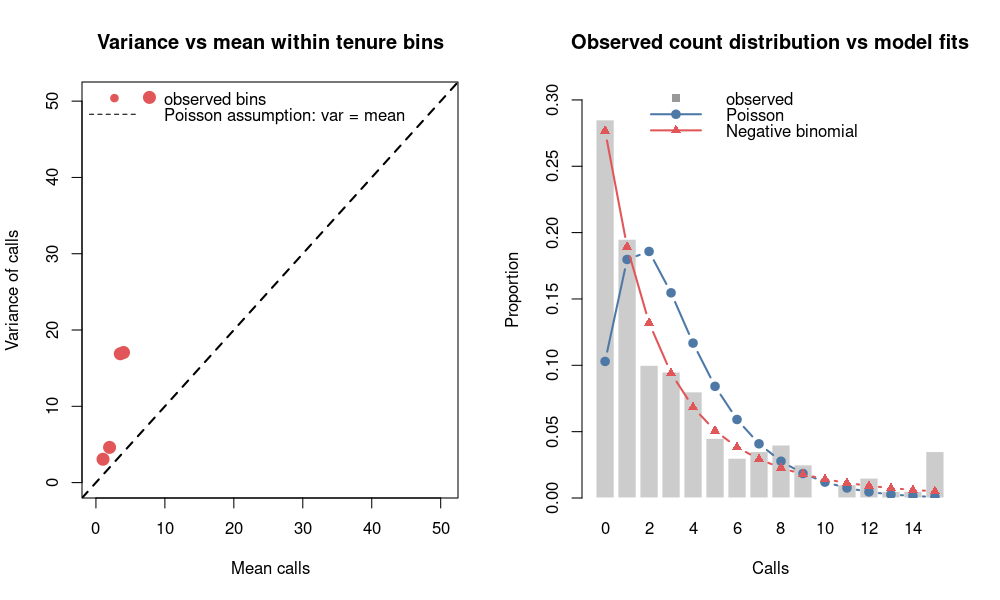

In [6]:
par(mfrow = c(1, 2))
breaks <- cut(support$Tenure, 5)
m <- tapply(support$Calls, breaks, mean); v <- tapply(support$Calls, breaks, var)
plot(m, v, pch = 19, cex = 1.6, col = "#E15759", xlim = c(0, max(m, v)), ylim = c(0, max(m, v)),
     main = "Variance vs mean within tenure bins", xlab = "Mean calls", ylab = "Variance of calls")
abline(0, 1, lty = 2, lwd = 2)
legend("topleft", c("observed bins", "Poisson assumption: var = mean"), col = c("#E15759", "black"),
       pch = c(19, NA), lty = c(NA, 2), bty = "n")

ks <- 0:15
obs  <- table(factor(pmin(support$Calls, 15), levels = ks)) / n
expP <- sapply(ks, function(k) mean(dpois(k, fitted(pois_fit))))
expN <- sapply(ks, function(k) mean(dnbinom(k, mu = fitted(nb_fit), size = nb_fit$theta)))
barplot(obs, names.arg = ks, col = "grey80", border = "white", ylim = c(0, max(obs, expP, expN) * 1.1),
        main = "Observed count distribution vs model fits", xlab = "Calls", ylab = "Proportion")
bx <- seq(0.7, by = 1.2, length.out = length(ks))
lines(bx, expP, type = "b", pch = 19, col = "#4E79A7", lwd = 2)
lines(bx, expN, type = "b", pch = 17, col = "#E15759", lwd = 2)
legend("topright", c("observed", "Poisson", "Negative binomial"), col = c("grey60", "#4E79A7", "#E15759"),
       pch = c(15, 19, 17), lwd = c(NA, 2, 2), bty = "n")

*Insight: All three models give nearly the same coefficient, but the Poisson standard error is far too small. Quasi-Poisson and negative binomial correct this. The negative binomial also reproduces the many zeros and the long right tail, which a Poisson model cannot.*

## 6. Other Advanced Techniques

1. **Overdispersion**: quasi-Poisson or negative binomial regression (above).
2. **Regularization**: with many predictors, **Lasso (L1)**, **Ridge (L2)** and **Elastic Net** shrink coefficients to prevent overfitting (`glmnet` package; Module M16 (Classical Machine Learning)).
3. **Interaction terms**: the effect of one predictor depends on another:
$$
\eta = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 X_1 X_2
$$
4. **Offsets**: model *rates* (e.g. accidents per 1,000 km driven) with `offset(log(exposure))`.
5. **Model diagnostics**: deviance residuals, leverage and influence points (Cook's distance).
6. **Extensions**: mixed-effects models (GLMM, `lme4`) for grouped data, and generalized additive models (GAM, `mgcv`) for smooth non-linear effects.

## Real-World Use Case or Analogy

- **Poisson GLM**: predicting the number of cars passing a traffic light per hour from the time of day.
- **Negative binomial GLM**: insurance claims per customer — most customers file none, a few file many.
- **Binomial GLM**: the probability that a customer buys a product, from their age and income.
- **Gamma GLM**: the size of insurance claims or hospital costs (always positive, right-skewed).

A GLM is like a **universal power adapter**: the same linear-model "plug" fits different "sockets" (distributions), with the link function as the adapter between them.